In [1]:
import torch
import torch.nn as nn
from torchvision import transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
import random
from torch.utils.data import Dataset, DataLoader
import os
from glob import glob
from PIL import Image
import json
from utils import moving_average

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(0)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [3]:
batch_size = 512
n_epochs = 10
n_classes = 5
crop_size = 32

In [4]:
class ImageDataset(Dataset):

    def __init__(self, split, transform=None):
        self.transform = transform

        # get the dictionnary with the crop's infos
        with open(f'data/dataset_crops/{split}_{crop_size}x{crop_size}_data.json', 'r', encoding='utf-8') as f:
            dico = json.load(f)

        # get all image paths, attributs and classes
        self.data = []

        for path in glob(os.path.join(f"data/dataset_crops/{split}", "**", "*.png"), recursive=True):
            filename = os.path.basename(path)      # "crop_i.png"
            crop_name = os.path.splitext(filename)[0]   # "crop_i"

            attributs = dico[crop_name]["attributs"]
            damage = dico[crop_name]["niveau de brûlé"]

            self.data.append((path, attributs, damage))


    def __len__(self):
        return len(self.data)


    def __getitem__(self, idx):
        img_path, attribut, label = self.data[idx]

        img = Image.open(img_path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        attribut = torch.tensor(attribut, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.int64)

        return img, attribut, label


# transformations ajoutées pour faire de la data augmentation autrement il y a de l'overfitting

def random_90_rotation(img):
    angles = [0, 90, 180, 270]
    return transforms.functional.rotate(img, angle=random.choice(angles))

transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(split="train", transform=transform)
val_dataset = ImageDataset(split="val", transform=transform)

In [5]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [6]:
# # Afficher une grille 3x3 d'exemples
# fig, axes = plt.subplots(3, 3, figsize=(8, 8))
# for i in range(3):
#     for j in range(3):
#         imgs, attributs, classes = next(iter(val_loader))
#         axes[i, j].imshow((imgs[0].permute(1, 2, 0).numpy() + 1)/2)
#         axes[i, j].set_title(f"Label: {classes[0]}")
#         axes[i, j].axis('off')
# plt.tight_layout()
# plt.show()

In [7]:
from torchvision.models import resnet18

resnet = resnet18(weights=None)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, n_classes)


resnet = resnet.to(device)

# load the resnet parameters
checkpoint = torch.load("weights/resnet_sur_crops_sat_32x32_checkpoint10.pth", map_location="cpu")
resnet.load_state_dict(checkpoint["model_state_dict"])

resnet.eval()

resnet_minus_last_layer = nn.Sequential(*list(resnet.children())[:-1])


total_params = sum(p.numel() for p in resnet.parameters())
print(f"Total parameters in the resnet: {total_params/1e6:.6f} million")

Total parameters in the resnet: 11.179077 million


In [8]:
import torch.nn.functional as F

class LinearSAE(nn.Module):

    def __init__(self, d_in, k, λ):
        super().__init__()
        self.enc = nn.Linear(d_in, k, bias=False)
        self.dec = nn.Linear(k, d_in, bias=False)
        self.λ   = λ

        nn.init.kaiming_normal_(self.enc.weight, nonlinearity='relu')
        nn.init.normal_(self.dec.weight, 0, 0.01)

    def forward(self, x):
        z = F.relu(self.enc(x))
        x_hat = self.dec(z)
        return x_hat, z

    def loss(self, x_hat, x, z):
        rec   = F.mse_loss(x_hat, x)
        spars = z.abs().mean()
        return rec + self.λ * spars, rec.item(), spars.item()


sae = LinearSAE(d_in=512, k=2048, λ=0.5).to(device)    # initialement λ=1e-3
optimizer_sae = torch.optim.AdamW(sae.parameters(), lr=3e-4, fused=True)   # initialement à lr=1e-3

total_params = sum(p.numel() for p in sae.parameters())
print(f"Total parameters in the sae: {total_params/1e6:.6f} million")

Total parameters in the sae: 2.097152 million


In [9]:
# class SparseAutoencoder(nn.Module):

#     def __init__(self, input_dim, hidden_dim):
#         super().__init__()
#         self.encoder = nn.Sequential(
#             nn.Linear(input_dim, hidden_dim),
#             nn.Sigmoid()
#         )
#         self.decoder = nn.Linear(hidden_dim, input_dim)

#     def forward(self, x):
#         z = self.encoder(x)
#         x_hat = self.decoder(z)
#         return x_hat, z

In [10]:
# def kl_divergence_bernouilli(rho, rho_hat):
#     rho_hat = torch.clamp(rho_hat, min=1e-10, max=1 - 1e-10)  # éviter les log(0)
#     return rho * torch.log(rho/rho_hat) + (1-rho) * torch.log((1-rho)/(1-rho_hat))

# def sparsity_penalty(a, rho=0.1, beta=0.5):
#     rho_hat = a.mean(dim=0)
#     kl_div = kl_divergence_bernouilli(rho, rho_hat)
#     return beta * torch.sum(kl_div)


 # loss = mse(x_hat, x) + sparsity_penalty(z)

In [11]:
# sparse_auto_encoder = SparseAutoencoder(512, 100).to(device)
# sparse_auto_encoder = LinearSAE(512).to(device)
# optimizer = torch.optim.AdamW(sparse_auto_encoder.parameters(), lr=learning_rate)
# mse = nn.MSELoss()


train_loss_list, val_loss_list = [], []
train_rec_loss_list, val_rec_loss_list = [], []
train_spars_loss_list, val_spars_loss_list = [], []
train_sparsity, val_sparsity = [], []

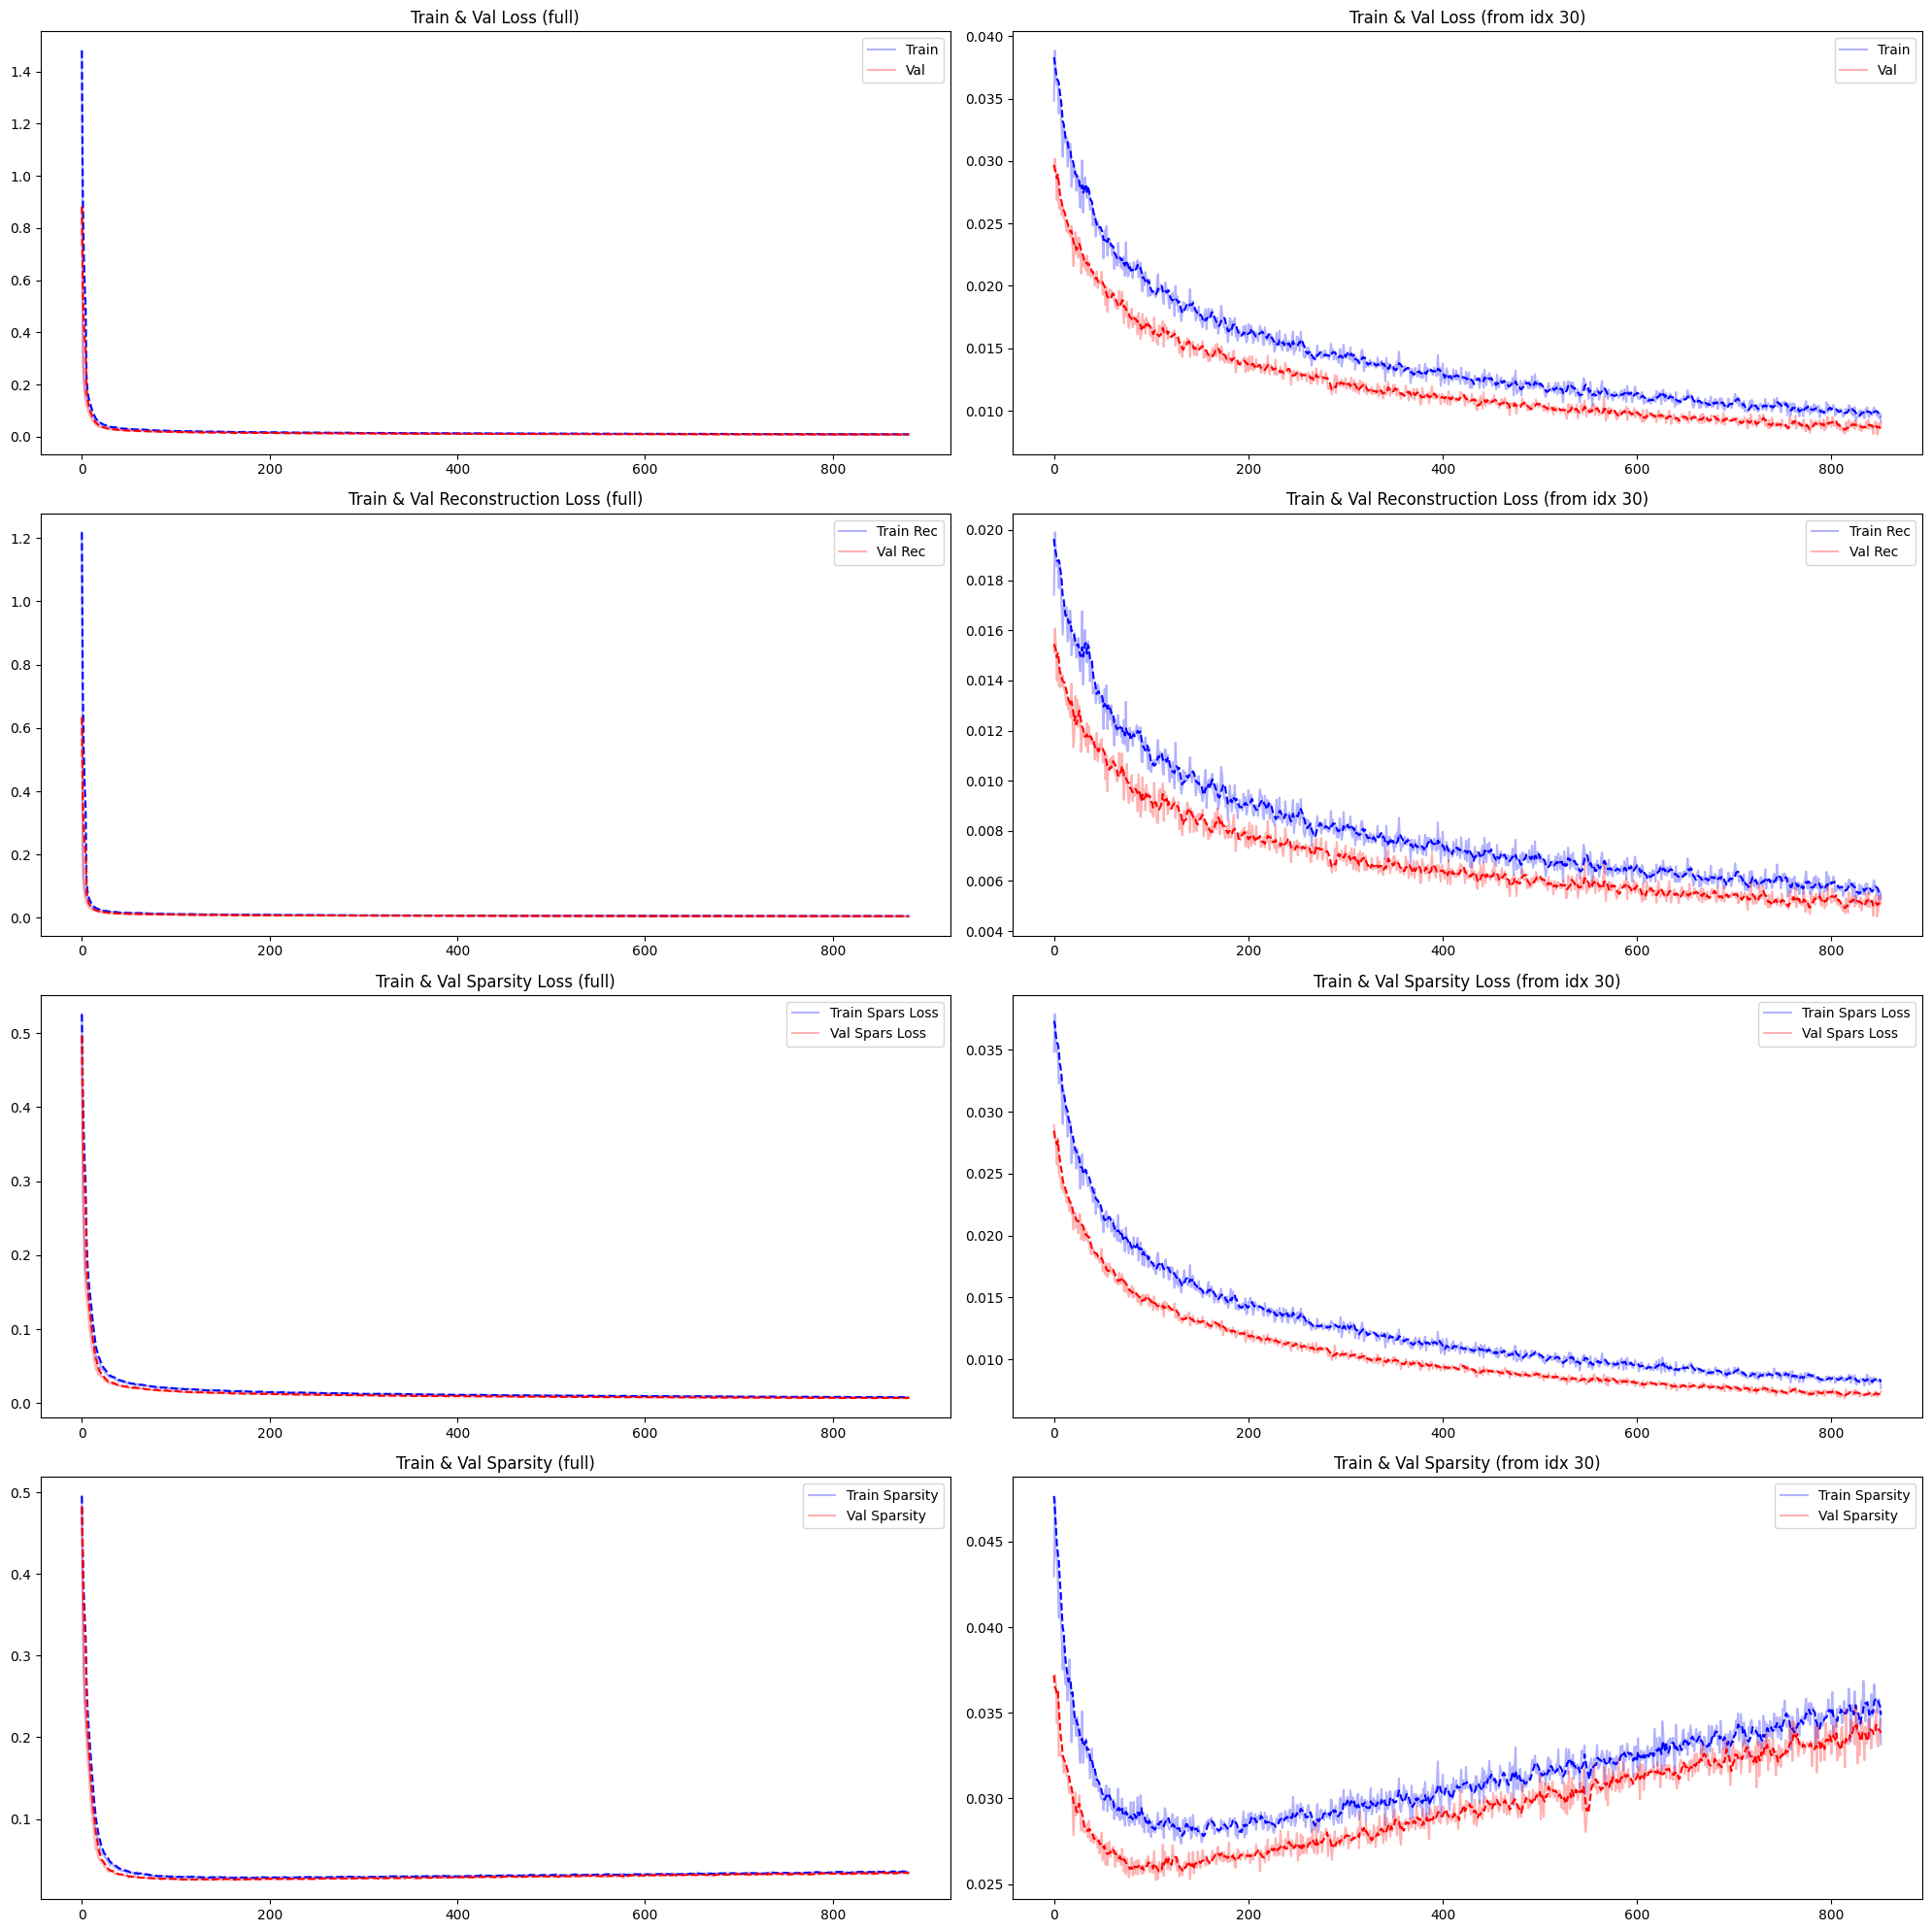

100%|██████████| 889/889 [00:51<00:00, 17.36it/s]


In [12]:
for epoch in range(n_epochs):
    for i, (imgs, attributs, classes) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

        with torch.no_grad():
            # get the activation of the layer before the output
            x = resnet_minus_last_layer(imgs)
            x = x.view(x.shape[0], -1)  # flatten the output

        # put it in the sparse autoencoder
        x_hat, z = sae(x)

        loss, rec_loss, spars_loss = sae.loss(x_hat, x, z)

        optimizer_sae.zero_grad()
        loss.backward()
        optimizer_sae.step()



        if i % 10 == 0:
            train_loss_list.append(loss.item())
            train_rec_loss_list.append(rec_loss)
            train_spars_loss_list.append(spars_loss)
            train_sparsity.append((z > 0).sum().item() / z.numel())

            # get val loss
            sae.eval()
            with torch.no_grad():
                try:
                    imgs, attributs, classes = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, attributs, classes = next(val_iterator)
                imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)
                x = resnet_minus_last_layer(imgs)
                x = x.view(x.shape[0], -1)  # flatten the output
                x_hat, z = sae(x)
                loss, rec_loss, spars_loss = sae.loss(x_hat, x, z)
                val_loss_list.append(loss.item())
                val_rec_loss_list.append(rec_loss)
                val_spars_loss_list.append(spars_loss)
                val_sparsity.append((z > 0).sum().item() / z.numel())
            sae.train()



        if epoch % 1 == 0 and i % 200 == 0:

            start_idx = 30

            # Lissage
            train_loss_list_smoothed = moving_average(train_loss_list, w=5)
            val_loss_list_smoothed = moving_average(val_loss_list, w=5)

            train_rec_loss_list_smoothed = moving_average(train_rec_loss_list, w=5)
            val_rec_loss_list_smoothed = moving_average(val_rec_loss_list, w=5)

            train_spars_loss_list_smoothed = moving_average(train_spars_loss_list, w=5)
            val_spars_loss_list_smoothed = moving_average(val_spars_loss_list, w=5)

            train_sparsity_smoothed = moving_average(train_sparsity, w=5)
            val_sparsity_smoothed = moving_average(val_sparsity, w=5)

            clear_output(wait=True)

            plt.figure(figsize=(20, 20))  # plus grand pour 8 sous-plots

            # --- Loss globale ---
            plt.subplot(4, 2, 1)
            plt.plot(train_loss_list, c="blue", alpha=0.3, label="Train")
            plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_loss_list, c="red", alpha=0.3, label="Val")
            plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Loss (full)")
            plt.legend()

            plt.subplot(4, 2, 2)
            plt.plot(train_loss_list[start_idx:], c="blue", alpha=0.3, label="Train")
            plt.plot(train_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_loss_list[start_idx:], c="red", alpha=0.3, label="Val")
            plt.plot(val_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Loss (from idx {start_idx})")
            plt.legend()

            # --- Reconstruction loss ---
            plt.subplot(4, 2, 3)
            plt.plot(train_rec_loss_list, c="blue", alpha=0.3, label="Train Rec")
            plt.plot(train_rec_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_rec_loss_list, c="red", alpha=0.3, label="Val Rec")
            plt.plot(val_rec_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Reconstruction Loss (full)")
            plt.legend()

            plt.subplot(4, 2, 4)
            plt.plot(train_rec_loss_list[start_idx:], c="blue", alpha=0.3, label="Train Rec")
            plt.plot(train_rec_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_rec_loss_list[start_idx:], c="red", alpha=0.3, label="Val Rec")
            plt.plot(val_rec_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Reconstruction Loss (from idx {start_idx})")
            plt.legend()

            # --- Sparsity loss ---
            plt.subplot(4, 2, 5)
            plt.plot(train_spars_loss_list, c="blue", alpha=0.3, label="Train Spars Loss")
            plt.plot(train_spars_loss_list_smoothed, c="blue", linestyle='--')
            plt.plot(val_spars_loss_list, c="red", alpha=0.3, label="Val Spars Loss")
            plt.plot(val_spars_loss_list_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Sparsity Loss (full)")
            plt.legend()

            plt.subplot(4, 2, 6)
            plt.plot(train_spars_loss_list[start_idx:], c="blue", alpha=0.3, label="Train Spars Loss")
            plt.plot(train_spars_loss_list_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_spars_loss_list[start_idx:], c="red", alpha=0.3, label="Val Spars Loss")
            plt.plot(val_spars_loss_list_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Sparsity Loss (from idx {start_idx})")
            plt.legend()

            # --- Sparsity (valeurs réelles, pas la loss) ---
            plt.subplot(4, 2, 7)
            plt.plot(train_sparsity, c="blue", alpha=0.3, label="Train Sparsity")
            plt.plot(train_sparsity_smoothed, c="blue", linestyle='--')
            plt.plot(val_sparsity, c="red", alpha=0.3, label="Val Sparsity")
            plt.plot(val_sparsity_smoothed, c="red", linestyle='--')
            plt.title("Train & Val Sparsity (full)")
            plt.legend()

            plt.subplot(4, 2, 8)
            plt.plot(train_sparsity[start_idx:], c="blue", alpha=0.3, label="Train Sparsity")
            plt.plot(train_sparsity_smoothed[start_idx:], c="blue", linestyle='--')
            plt.plot(val_sparsity[start_idx:], c="red", alpha=0.3, label="Val Sparsity")
            plt.plot(val_sparsity_smoothed[start_idx:], c="red", linestyle='--')
            plt.title(f"Train & Val Sparsity (from idx {start_idx})")
            plt.legend()

            plt.tight_layout()
            plt.show()


In [ ]:
# # sauvegarder les poids du modèle et les paramètres d'entraînement

# torch.save({
#     'epoch': epoch+1,
#     'model_state_dict': sae.to("cpu").state_dict(),
#     'optimizer_state_dict': optimizer_sae.state_dict(),
#     'loss': torch.tensor([train_loss_list_smoothed[-100:]]).mean(),
# }, f"weights/sae_{crop_size}x{crop_size}_checkpoint2.pth")

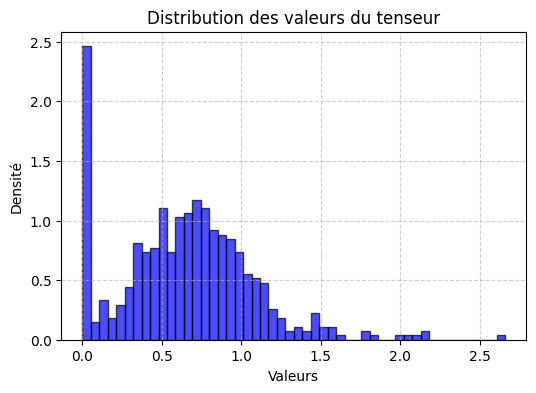

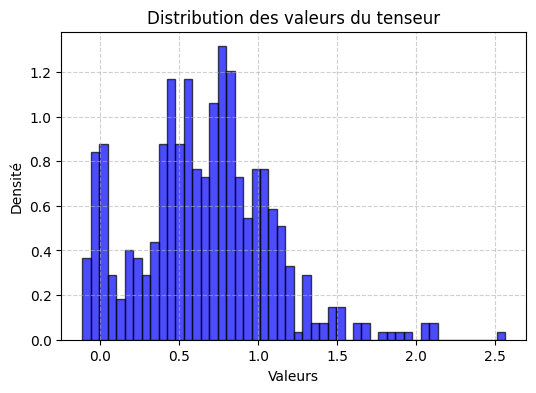

In [20]:
imgs, attributs, classes = next(iter(val_loader))

imgs, attributs, classes = imgs.to(device), attributs.to(device), classes.to(device)

# get the activation of the layer before the output
x = resnet_minus_last_layer(imgs)
x = x.view(x.shape[0], -1)  # flatten the output

x_hat, z = sae(x)




# Tracer un histogramme
plt.figure(figsize=(6,4))
plt.hist(x[0].detach().cpu().numpy(), bins=50, density=True, alpha=0.7, color="blue", edgecolor="black")
plt.title("Distribution des valeurs du tenseur")
plt.xlabel("Valeurs")
plt.ylabel("Densité")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


# Tracer un histogramme
plt.figure(figsize=(6,4))
plt.hist(x_hat[0].detach().cpu().numpy(), bins=50, density=True, alpha=0.7, color="blue", edgecolor="black")
plt.title("Distribution des valeurs du tenseur")
plt.xlabel("Valeurs")
plt.ylabel("Densité")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()



In [21]:
x0, x_hat0 = x[0], x_hat[0]

for i in range(10):
    print(x0[i].item(), x_hat0[i].item(), (x0[i].item() - x_hat0[i].item())**2)

0.7598779797554016 0.7859323620796204 0.0006788308382965624
0.9415425062179565 0.9697452783584595 0.0007953963564091282
0.47180411219596863 0.48404499888420105 0.0001498393069141457
0.9436981678009033 0.9775074124336243 0.0011430650226351702
0.7675681710243225 0.7982425689697266 0.0009409186893130084
0.41588136553764343 0.47221338748931885 0.003173296697164041
0.5967792868614197 0.616566002368927 0.0003915141105750308
0.7987956404685974 0.8481688499450684 0.0024377138140074806
0.43361884355545044 0.5002212524414062 0.0044358808694120455
0.8826227188110352 0.7441929578781128 0.01916279871194604


In [16]:
print((z > 0).sum().item()/z.numel())
print(z.flatten().tolist()[:100])

0.03444194793701172
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.039024099707603455, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.005463007837533951, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.6928539872169495, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.07643303275108337, 0.0, 0.0, 0.0, 0.0]
